# Background

- **Author**: 許以琳
- **Created At**: 2026-11-10
- **Research Motivation and Context (why are we interested in the findings?)：** 與 [candidate_cluster_taipei_kaohsiung.ipynb](candidate_cluster_taipei_kaohsiung.ipynb) 相同的臺北＋高雄 198 人、相同的 k-means 與 PAM 設定，但改用 **G6 已依組員張睿庠資料更新** 的分析檔 `data/processed/candidates_scope_g1_g6_20261110.csv`（產生方式見 [G6 更新處理筆記本](../data/code/apply_g6_teammate_20261110.ipynb)：31 人 G6 由 0 改為 1，北高 198 人中有 26 人）。舊版 G6 的結果保留在原 notebook；本 notebook 也重算舊版以便比較。
- **Main Findings and Takeaways：** G6 改用組員資料後（北高 198 人中 26 人由 0 改 1，政治家族比例 19.2% → 32.3%）：(1) k-means k = 4 的分群完全不變（和舊版 ARI 1.000），仍是國民黨／大學學歷跨黨／民進黨／無黨籍小黨，只有各群的政治家族比例上升；(2) PAM 的切點變成 k = 3（離連線 13.16，k = 4 為 12.94，幾乎相同）：男性、國民黨為主（88）、女性＋政治家族（63，女性 81%、政治家族 75%）、大學學歷＋無黨籍為主（47）；k = 4 為年長男性國民黨為主（70）、女性＋政治家族（51，女性 90%、政治家族 77%）、大學學歷（45）、首次參選（32，91%）。(3) PAM k = 3 的穩定度明顯提高（抽樣重跑平均 ARI 0.724、排除約略年齡後 0.699），k = 4 仍不穩（0.447、0.221）；PAM k = 4 與 G5×G6 組合的 ARI 為 0.301。
- **Future Direction：** 後續分群與策略比較改用本版 G6；沈伯洋、陳瑩、許甫、吳銘賜 4 人的 G6 定義邊界仍可討論。
<!-- Deliver the ipynb in finding/ directly for review, retaining actual outputs.
HTML is not required and is produced only when separately requested. Use the
student's requested or existing filename, or a descriptive basename. Created At
is the fixed creation date. Follow the project-root FINDING-RULES.md for handoff
and external-action scope. -->


In [1]:
# Load packages here
from pathlib import Path
import hashlib
from math import comb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams["font.sans-serif"] = ["Microsoft JhengHei", "Microsoft YaHei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
# 本機 Windows 的應用程式控制原則封鎖 scikit-learn 的編譯元件，k-means、PAM、輪廓係數與 ARI 以 numpy 實作（與先前 notebook 相同）。


In [2]:
# Load input data here and please finish all the data manipulation here.
def find_project_root(start=None):
    start = Path.cwd() if start is None else Path(start)
    for candidate in (start.resolve(), *start.resolve().parents):
        if (candidate / "AGENTS.md").is_file() and (candidate / "templates").is_dir():
            return candidate
    raise FileNotFoundError("請在含 AGENTS.md 與 templates/ 的專案內開啟本 notebook。")

PROJECT_ROOT = find_project_root()
DATA_REL = "data/processed/candidates_scope_g1_g6_20261110.csv"
EXPECTED_SHA256 = "ff2a7214ccaeb86a2ea2b5caf1883cb07aa7f37454505d76f221b6f6ac0c7ea0"
OLD_REL = "data/processed/candidates_scope_g1_g6_20261108.csv"
OLD_SHA256 = "5af31805a707502198004aad222ac9a61c4309d9bc27cfa1c059450d74b8e6a6"
data_path = PROJECT_ROOT / DATA_REL
assert data_path.is_file(), f"找不到輸入檔：{DATA_REL}"
actual = hashlib.sha256(data_path.read_bytes()).hexdigest()
assert actual == EXPECTED_SHA256, f"輸入檔內容已變動（{actual}），請先確認新版本再分析。"

raw = pd.read_csv(data_path, dtype=str, encoding="utf-8-sig")
old_path = PROJECT_ROOT / OLD_REL
assert hashlib.sha256(old_path.read_bytes()).hexdigest() == OLD_SHA256, "舊版分析檔內容已變動"
raw_old = pd.read_csv(old_path, dtype=str, encoding="utf-8-sig")
need = ["candidate_key", "candidate_name", "office_type", "county_city", "G1_age_2026_minus_birth_year",
        "G1_age_basis", "G2_sex", "G3_education_level", "G4_party",
        "G5_first_time_any_elected_office", "G6_political_family"]
assert set(need) <= set(raw.columns) and raw["candidate_key"].is_unique

def prep(frame):
    d = frame[need].copy().reset_index(drop=True)
    d["age"] = pd.to_numeric(d["G1_age_2026_minus_birth_year"], errors="raise")
    d["sex"] = d["G2_sex"]
    d["education"] = d["G3_education_level"]
    d["party"] = d["G4_party"]
    d["first_time"] = d["G5_first_time_any_elected_office"].map({"1": "首次參選", "0": "曾參選"})
    d["political_family"] = d["G6_political_family"].map({"1": "有", "0": "無"})
    return d

df_old = prep(raw_old[raw_old["county_city"].isin(["臺北市", "高雄市"])])   # 舊版 G6（對照用）
df = prep(raw[raw["county_city"].isin(["臺北市", "高雄市"])])  # 本分析：只留臺北、高雄
analysis_vars = ["age", "sex", "education", "party", "first_time", "political_family"]
assert df[analysis_vars].notna().all().all()
assert (df_old["candidate_key"].to_numpy() == df["candidate_key"].to_numpy()).all()
print("分析樣本（臺北＋高雄）：", len(df), "人；G6 由舊版改為 1 的人數：", int(((df_old["political_family"] == "無") & (df["political_family"] == "有")).sum()))
print(pd.crosstab(df["county_city"], df["office_type"], margins=True, margins_name="合計"))
df[["candidate_name", "office_type", "county_city"] + analysis_vars].head(10)


分析樣本（臺北＋高雄）： 198 人；G6 由舊版改為 1 的人數： 26
office_type  直轄市議員  直轄市長   合計
county_city                  
臺北市             90     6   96
高雄市             97     5  102
合計             187    11  198


,candidate_name,office_type,county_city,age,sex,education,party,first_time,political_family
0,郭璽,直轄市長,臺北市,68,男,大學,其他政黨,曾參選,無
1,沈伯洋,直轄市長,臺北市,44,男,研究所,民進黨,曾參選,有
2,蕭文乾,直轄市長,臺北市,52,男,研究所,其他政黨,曾參選,無
3,唐新民,直轄市長,臺北市,76,男,研究所,其他政黨,曾參選,無
4,蔣萬安,直轄市長,臺北市,48,男,研究所,國民黨,曾參選,有
5,林志成,直轄市長,臺北市,61,男,研究所,無黨籍／未經政黨推薦,曾參選,無
6,張靜,直轄市長,高雄市,70,男,大學,其他政黨,曾參選,無
7,賴瑞隆,直轄市長,高雄市,53,男,研究所,民進黨,曾參選,無
8,王肇民,直轄市長,高雄市,63,男,大學,無黨籍／未經政黨推薦,首次參選,無
9,柯志恩,直轄市長,高雄市,64,女,研究所,國民黨,曾參選,有


In [3]:
# Before conducting the analysis, report summary statistics for all variables used.
LABELS = {"age": "G1 年齡（2026 − 出生年）", "sex": "G2 性別", "education": "G3 最高已完成學歷",
          "party": "G4 政黨（登記推薦）", "first_time": "G5 是否首次參選任何民選公職",
          "political_family": "G6 政治家族（配偶或三親等內親屬任公職）"}
N = len(df)
d = df["age"].describe(percentiles=[.25, .5, .75])
print(f"表 1　數值變數摘要統計（N = {N}）")
display(pd.DataFrame({"平均": [d["mean"]], "最小值": [d["min"]], "第25百分位": [d["25%"]], "中位數": [d["50%"]],
                      "第75百分位": [d["75%"]], "最大值": [d["max"]], "標準差": [d["std"]], "有效 N": [int(d["count"])],
                      "缺值 N": [int(df["age"].isna().sum())]}, index=[LABELS["age"]]).round(2))
rows = []
for v in ["sex", "education", "party", "first_time", "political_family"]:
    vc = df[v].value_counts(); nn = int(df[v].notna().sum())
    for cat, cnt in vc.head(10).items():
        rows.append({"變數": LABELS[v], "類別": cat, "人數": int(cnt), "百分比（%）": round(100 * cnt / nn, 1),
                     "有效 N": nn, "缺值 N": int(df[v].isna().sum())})
print(f"表 2　類別變數摘要統計（N = {N}；百分比分母為該變數非缺值人數）")
display(pd.DataFrame(rows).set_index(["變數", "類別"]))


表 1　數值變數摘要統計（N = 198）


,平均,最小值,第25百分位,中位數,第75百分位,最大值,標準差,有效 N,缺值 N
G1 年齡（2026 − 出生年）,50.32,24.0,42.0,49.0,58.75,83.0,11.77,198,0


表 2　類別變數摘要統計（N = 198；百分比分母為該變數非缺值人數）


人數  百分比（%）  有效 N  缺值 N
變數                    類別                                 
G2 性別                 男           118    59.6   198     0
                      女            80    40.4   198     0
G3 最高已完成學歷            研究所         127    64.1   198     0
                      大學           52    26.3   198     0
                      大學以下         19     9.6   198     0
G4 政黨（登記推薦）           國民黨          68    34.3   198     0
                      民進黨          63    31.8   198     0
                      無黨籍／未經政黨推薦   39    19.7   198     0
                      其他政黨         21    10.6   198     0
                      民眾黨           7     3.5   198     0
G5 是否首次參選任何民選公職       曾參選         158    79.8   198     0
                      首次參選         40    20.2   198     0
G6 政治家族（配偶或三親等內親屬任公職） 無           134    67.7   198     0
                      有            64    32.3   198     0

### The actual analysis starts below

**設定與舊版 G6 的北高分析完全相同，只換 G6。**

- **k-means**：G1 年齡以本樣本的最小、最大值縮放到 0–1；G2 女性＝1；G3 學歷拆 3 欄、G4 政黨拆 5 欄（0/1）；G5、G6 為 0/1，共 12 欄。每個 k 試 50 組 k-means++ 起點，取群內平方和（WCSS）最小的解。
- **PAM**：Gower 距離，年齡差距 ÷ 本樣本年齡全距，其餘五個類別變數相同 0、不同 1，六項平均；BUILD＋SWAP 求代表人物（medoid）。

**選 k。** 兩種方法都跑 k = 1–10，以平移首尾連線找 elbow 切點，並看平均輪廓係數與最小群人數。最終分群採各自的 elbow 切點；若切點不是 4，另列 k = 4 的結果以便和 267 人版本比較。

**穩定度與比較。** 抽 80% 重跑 50 次、排除年齡來自報導或約略值者重跑；並和舊版 G6 的分群比較（ARI，同一批 198 人）。


In [4]:
PARTIES = ["國民黨", "民進黨", "民眾黨", "其他政黨", "無黨籍／未經政黨推薦"]

def feat(frame):
    amin, amax = frame["age"].min(), frame["age"].max()
    X = pd.DataFrame(index=frame.index)
    X["age"] = (frame["age"] - amin) / (amax - amin)
    X["female"] = (frame["sex"] == "女").astype(int)
    for lvl in ["大學以下", "大學", "研究所"]:
        X[lvl] = (frame["education"] == lvl).astype(int)
    for p in PARTIES:
        X[p] = (frame["party"] == p).astype(int)
    X["first"] = (frame["first_time"] == "首次參選").astype(int)
    X["family"] = (frame["political_family"] == "有").astype(int)
    return X.values.astype(float)

def gower(frame, age_range=None):
    a = frame["age"].to_numpy(float)
    r = (a.max() - a.min()) if age_range is None else age_range
    Dm = np.abs(a[:, None] - a[None, :]) / r
    for v in ["sex", "education", "party", "first_time", "political_family"]:
        x = frame[v].to_numpy()
        Dm = Dm + (x[:, None] != x[None, :])
    return Dm / 6

def kmeans(X, k, n_init=50, max_iter=300, tol=1e-8, seed=0):
    rng = np.random.default_rng(seed)
    best = None
    for _ in range(n_init):
        Cc = [X[rng.integers(len(X))]]
        for _ in range(1, k):
            d2 = np.min(((X[:, None, :] - np.array(Cc)[None]) ** 2).sum(-1), axis=1)
            Cc.append(X[rng.choice(len(X), p=d2 / d2.sum())] if d2.sum() > 0 else X[rng.integers(len(X))])
        Cc = np.array(Cc, dtype=float)
        for _ in range(max_iter):
            lab = ((X[:, None, :] - Cc[None]) ** 2).sum(-1).argmin(1)
            newC = np.array([X[lab == j].mean(0) if (lab == j).any() else Cc[j] for j in range(k)])
            shift = ((newC - Cc) ** 2).sum()
            Cc = newC
            if shift <= tol:
                break
        lab = ((X[:, None, :] - Cc[None]) ** 2).sum(-1).argmin(1)
        inertia = ((X - Cc[lab]) ** 2).sum()
        if best is None or inertia < best[1] - 1e-12:
            best = (lab, inertia)
    return best

def pam(Dm, k, max_iter=200):
    n = len(Dm)
    med = [int(Dm.sum(1).argmin())]
    while len(med) < k:
        dmin = Dm[:, med].min(1)
        gain = np.maximum(dmin[None, :] - Dm, 0).sum(1)
        gain[med] = -1
        med.append(int(gain.argmax()))
    med = np.array(med)
    for _ in range(max_iter):
        dm = Dm[:, med]
        order = np.argsort(dm, axis=1)
        near = order[:, 0]
        d1 = dm[np.arange(n), near]
        d2 = dm[np.arange(n), order[:, 1]] if k > 1 else np.full(n, np.inf)
        cost = d1.sum()
        best = (0.0, None, None)
        nonmed = np.setdiff1d(np.arange(n), med)
        for i in range(k):
            base = np.where(near == i, d2, d1)
            newc = np.minimum(Dm[nonmed, :], base[None, :]).sum(1) - cost
            j = newc.argmin()
            if newc[j] < best[0] - 1e-12:
                best = (newc[j], i, nonmed[j])
        if best[1] is None:
            break
        med[best[1]] = best[2]
    lab = Dm[:, med].argmin(1)
    return lab, Dm[np.arange(n), med[lab]].sum(), med

def silhouette_D(Dm, lab):
    s = np.zeros(len(Dm))
    for i in range(len(Dm)):
        same = lab == lab[i]
        if same.sum() <= 1:
            continue
        a = Dm[i, same].sum() / (same.sum() - 1)
        b = min(Dm[i, lab == c].mean() for c in np.unique(lab) if c != lab[i])
        s[i] = 0 if max(a, b) == 0 else (b - a) / max(a, b)
    return s.mean()

def eucl(X):
    return np.sqrt(((X[:, None, :] - X[None]) ** 2).sum(-1))

def ari(a, b):
    ct = pd.crosstab(pd.Series(list(a)), pd.Series(list(b))).values
    sij = sum(comb(int(n), 2) for n in ct.ravel())
    sa = sum(comb(int(n), 2) for n in ct.sum(1)); sb = sum(comb(int(n), 2) for n in ct.sum(0))
    tot = comb(int(ct.sum()), 2); e = sa * sb / tot
    return (sij - e) / ((sa + sb) / 2 - e)

def tangent(series):
    ks = np.array(series.index, float)
    chord = series.iloc[0] + (series.iloc[-1] - series.iloc[0]) / (ks[-1] - ks[0]) * (ks - ks[0])
    gap = pd.Series(chord - series.values, index=series.index)
    return int(gap.idxmax()), gap

def relabel(lab):
    order = pd.Series(lab).value_counts().index.tolist()
    return pd.Series(lab).map({o: i + 1 for i, o in enumerate(order)}).values

X = feat(df); D = gower(df); Eu = eucl(X)
print(f"k-means 特徵矩陣 {X.shape}；Gower 距離 {D.shape}，兩兩平均 {D[np.triu_indices(len(D), 1)].mean():.3f}")

rows = []
for k in range(1, 11):
    lk, wk = kmeans(X, k, n_init=50, seed=20261110 + k)
    lp, cp, _ = pam(D, k)
    rows.append({"k": k, "k-means WCSS": wk, "k-means 輪廓係數": silhouette_D(Eu, lk) if k > 1 else np.nan,
                 "k-means 最小群": int(np.bincount(lk, minlength=k).min()),
                 "PAM 總成本": cp, "PAM 輪廓係數": silhouette_D(D, lp) if k > 1 else np.nan,
                 "PAM 最小群": int(np.bincount(lp, minlength=k).min())})
ch = pd.DataFrame(rows).set_index("k")
ch.insert(1, "k-means 減少（%）", 100 * (-ch["k-means WCSS"].diff()) / ch["k-means WCSS"].shift())
ch.insert(5, "PAM 減少（%）", 100 * (-ch["PAM 總成本"].diff()) / ch["PAM 總成本"].shift())
K_KM, gap_km = tangent(ch["k-means WCSS"])
K_PAM, gap_pam = tangent(ch["PAM 總成本"])
print(f"表 3　臺北＋高雄：k = 1–10 的 WCSS／總成本、輪廓係數與最小群（N = {len(df)}）")
display(ch.round(3))
print(f"平移首尾連線切點：k-means k = {K_KM}（離連線 {gap_km.max():.2f}）；PAM k = {K_PAM}（離連線 {gap_pam.max():.2f}）")
print("k-means 各 k 離連線距離：", gap_km.round(2).to_dict())
print("PAM 各 k 離連線距離：", gap_pam.round(2).to_dict())


k-means 特徵矩陣 (198, 12)；Gower 距離 (198, 198)，兩兩平均 0.454


表 3　臺北＋高雄：k = 1–10 的 WCSS／總成本、輪廓係數與最小群（N = 198）


,k-means WCSS,k-means 減少（%）,k-means 輪廓係數,k-means 最小群,PAM 總成本,PAM 減少（%）,PAM 輪廓係數,PAM 最小群
k,,,,,,,,
1,376.259,NaN,NaN,198,69.602,NaN,NaN,198
2,300.112,20.238,0.232,71,54.362,21.896,0.247,71
3,254.416,15.226,0.220,54,46.960,13.615,0.206,47
4,217.194,14.630,0.270,43,42.438,9.631,0.209,32
5,195.012,10.213,0.290,19,38.907,8.321,0.186,29
6,181.863,6.742,0.300,16,35.121,9.729,0.213,22
7,170.537,6.228,0.290,15,32.698,6.901,0.211,18
8,159.765,6.316,0.297,16,30.551,6.566,0.231,18
9,147.272,7.819,0.302,9,28.768,5.834,0.241,15


平移首尾連線切點：k-means k = 4（離連線 78.29）；PAM k = 3（離連線 13.16）
k-means 各 k 離連線距離： {1: 0.0, 2: 49.22, 3: 68.0, 4: 78.29, 5: 73.55, 6: 59.78, 7: 44.18, 8: 28.03, 9: 13.6, 10: 0.0}
PAM 各 k 離連線距離： {1: 0.0, 2: 10.5, 3: 13.16, 4: 12.94, 5: 11.73, 6: 10.78, 7: 8.46, 8: 5.87, 9: 2.91, 10: 0.0}


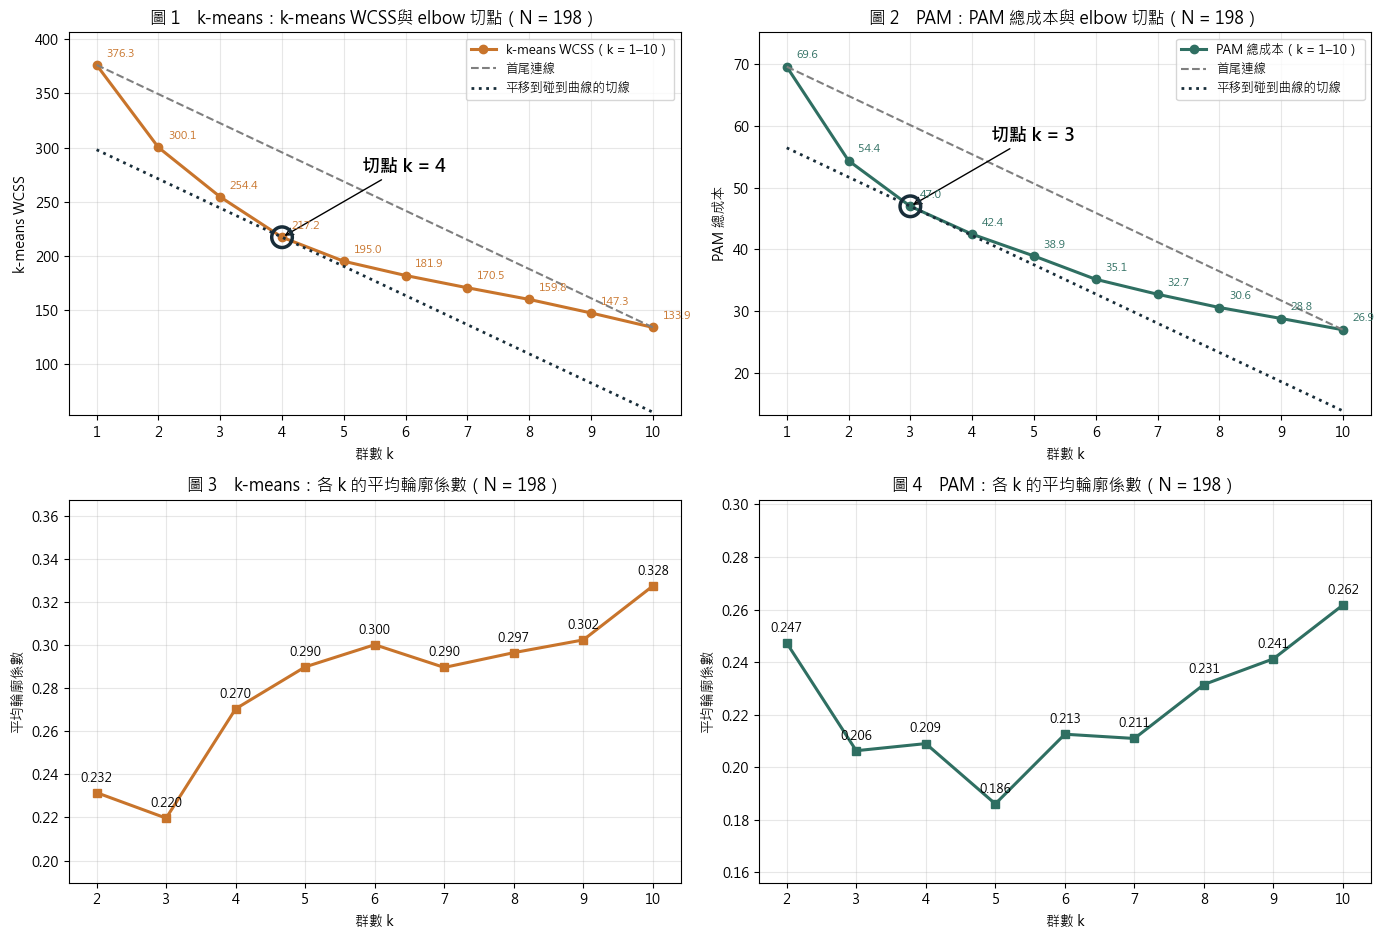

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9.5))
for col_i, (col, sil, kk, gap, color, name) in enumerate([
        ("k-means WCSS", "k-means 輪廓係數", K_KM, gap_km, "#C8742B", "k-means"),
        ("PAM 總成本", "PAM 輪廓係數", K_PAM, gap_pam, "#2f6f62", "PAM")]):
    ax = axes[0, col_i]
    w = ch[col]; ks = np.array(w.index, float)
    chord = w.iloc[0] + (w.iloc[-1] - w.iloc[0]) / 9 * (ks - 1)
    ax.plot(ks, w.values, marker="o", color=color, linewidth=2.2, label=f"{col}（k = 1–10）")
    ax.plot([1, 10], [w.iloc[0], w.iloc[-1]], linestyle="--", color="#7f7f7f", label="首尾連線")
    ax.plot(ks, chord - gap.max(), linestyle=":", color="#182D39", linewidth=2, label="平移到碰到曲線的切線")
    ax.scatter([kk], [w.loc[kk]], s=220, facecolors="none", edgecolors="#182D39", linewidths=2.5, zorder=4)
    ax.annotate(f"切點 k = {kk}", xy=(kk, w.loc[kk]), xytext=(kk + 1.3, w.loc[kk] + (w.max() - w.min()) * 0.25),
                fontsize=13, fontweight="bold", arrowprops=dict(arrowstyle="->"))
    for k, v in w.items():
        ax.annotate(f"{v:.1f}", (k, v), textcoords="offset points", xytext=(7, 6), fontsize=8, color=color)
    ax.set_title(f"圖 {1 + col_i}　{name}：{col}與 elbow 切點（N = {len(df)}）")
    ax.set_xlabel("群數 k"); ax.set_ylabel(col); ax.set_xticks(ks)
    ax.set_ylim(min((chord - gap.max()).min(), w.min()) * 0.95, w.max() * 1.08)
    ax.legend(loc="upper right", fontsize=9); ax.grid(alpha=.3)
    ax = axes[1, col_i]
    s = ch[sil].dropna()
    ax.plot(s.index, s.values, marker="s", color=color, linewidth=2.2)
    for k, v in s.items():
        ax.annotate(f"{v:.3f}", (k, v), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=9)
    ax.set_title(f"圖 {3 + col_i}　{name}：各 k 的平均輪廓係數（N = {len(df)}）")
    ax.set_xlabel("群數 k"); ax.set_ylabel("平均輪廓係數"); ax.set_xticks(s.index)
    ax.set_ylim(s.min() - 0.03, s.max() + 0.04); ax.grid(alpha=.3)
fig.tight_layout()
asset_dir = PROJECT_ROOT / "finding" / "candidate_cluster_taipei_kaohsiung_g6v2_assets"
asset_dir.mkdir(exist_ok=True)
fig.savefig(asset_dir / "tk_choose_k.png", dpi=200)
plt.show()


In [6]:
def describe(g):
    col = {"人數": len(g), "平均年齡": g["age"].mean(), "女性（%）": 100 * (g["sex"] == "女").mean()}
    for lvl in ["研究所", "大學", "大學以下"]:
        col[f"學歷：{lvl}（%）"] = 100 * (g["education"] == lvl).mean()
    for pty in PARTIES:
        col[f"政黨：{pty}（%）"] = 100 * (g["party"] == pty).mean()
    col["首次參選（%）"] = 100 * (g["first_time"] == "首次參選").mean()
    col["政治家族（%）"] = 100 * (g["political_family"] == "有").mean()
    col["首長（%）"] = 100 * (g["office_type"] == "直轄市長").mean()
    col["高雄（%）"] = 100 * (g["county_city"] == "高雄市").mean()
    return col

results = {}
versions = [("k-means", K_KM), ("PAM", K_PAM)]
if K_KM != 4:
    versions.append(("k-means", 4))
if K_PAM != 4:
    versions.append(("PAM", 4))
for method, k in versions:
    if method == "k-means":
        lab = relabel(kmeans(X, k, n_init=50, seed=20261110 + k)[0]); med = None
    else:
        l, _, med = pam(D, k); lab = relabel(l)
    name = f"{method} k = {k}"
    results[name] = {"lab": lab, "k": k, "method": method, "med": med, "raw": None if med is None else l}
    df["_c"] = lab
    prof = pd.DataFrame({f"第 {c} 群": describe(g) for c, g in df.groupby("_c")})
    prof["全樣本"] = pd.Series(describe(df))
    results[name]["profile"] = prof
    print(f"表　{name}（臺北＋高雄，N = {len(df)}）各群特徵；百分比分母為該群人數")
    display(prof.round(1))
    if med is not None:
        rel = {o: i + 1 for i, o in enumerate(pd.Series(l).value_counts().index.tolist())}
        mt = df.iloc[med][["candidate_name", "office_type", "county_city", "age", "sex", "education", "party", "first_time", "political_family"]].copy()
        mt.insert(0, "群別", [f"第 {rel[i]} 群" for i in range(k)])
        print(f"　{name} 各群代表人物（medoid）")
        display(mt.sort_values("群別").set_index("群別"))
df = df.drop(columns="_c")


表　k-means k = 4（臺北＋高雄，N = 198）各群特徵；百分比分母為該群人數


,第 1 群,第 2 群,第 3 群,第 4 群,全樣本
人數,54.0,52.0,49.0,43.0,198.0
平均年齡,53.1,47.0,48.9,52.5,50.3
女性（%）,46.3,40.4,40.8,32.6,40.4
學歷：研究所（%）,88.9,0.0,98.0,72.1,64.1
學歷：大學（%）,0.0,100.0,0.0,0.0,26.3
學歷：大學以下（%）,11.1,0.0,2.0,27.9,9.6
政黨：國民黨（%）,100.0,26.9,0.0,0.0,34.3
政黨：民進黨（%）,0.0,26.9,100.0,0.0,31.8
政黨：民眾黨（%）,0.0,9.6,0.0,4.7,3.5
政黨：其他政黨（%）,0.0,17.3,0.0,27.9,10.6


表　PAM k = 3（臺北＋高雄，N = 198）各群特徵；百分比分母為該群人數


,第 1 群,第 2 群,第 3 群,全樣本
人數,88.0,63.0,47.0,198.0
平均年齡,51.1,46.1,54.6,50.3
女性（%）,17.0,81.0,29.8,40.4
學歷：研究所（%）,84.1,73.0,14.9,64.1
學歷：大學（%）,9.1,20.6,66.0,26.3
學歷：大學以下（%）,6.8,6.3,19.1,9.6
政黨：國民黨（%）,54.5,27.0,6.4,34.3
政黨：民進黨（%）,23.9,57.1,12.8,31.8
政黨：民眾黨（%）,1.1,3.2,8.5,3.5
政黨：其他政黨（%）,10.2,3.2,21.3,10.6


　PAM k = 3 各群代表人物（medoid）


,candidate_name,office_type,county_city,age,sex,education,party,first_time,political_family
群別,,,,,,,,,
第 1 群,曾獻瑩,直轄市議員,臺北市,50,男,研究所,國民黨,曾參選,無
第 2 群,鍾佩玲,直轄市議員,臺北市,47,女,研究所,民進黨,曾參選,有
第 3 群,薛兆基,直轄市議員,高雄市,58,男,大學,無黨籍／未經政黨推薦,曾參選,無


表　PAM k = 4（臺北＋高雄，N = 198）各群特徵；百分比分母為該群人數


,第 1 群,第 2 群,第 3 群,第 4 群,全樣本
人數,70.0,51.0,45.0,32.0,198.0
平均年齡,57.4,47.4,46.8,44.4,50.3
女性（%）,22.9,90.2,24.4,21.9,40.4
學歷：研究所（%）,81.4,78.4,17.8,68.8,64.1
學歷：大學（%）,4.3,15.7,77.8,18.8,26.3
學歷：大學以下（%）,14.3,5.9,4.4,12.5,9.6
政黨：國民黨（%）,57.1,33.3,17.8,9.4,34.3
政黨：民進黨（%）,14.3,52.9,44.4,18.8,31.8
政黨：民眾黨（%）,1.4,3.9,6.7,3.1,3.5
政黨：其他政黨（%）,10.0,3.9,17.8,12.5,10.6


　PAM k = 4 各群代表人物（medoid）


,candidate_name,office_type,county_city,age,sex,education,party,first_time,political_family
群別,,,,,,,,,
第 1 群,吳利成,直轄市議員,高雄市,57,男,研究所,國民黨,曾參選,無
第 2 群,鍾佩玲,直轄市議員,臺北市,47,女,研究所,民進黨,曾參選,有
第 3 群,陳賢蔚,直轄市議員,臺北市,49,男,大學,民進黨,曾參選,無
第 4 群,陳彥廷,直轄市議員,臺北市,43,男,研究所,無黨籍／未經政黨推薦,首次參選,無


表　穩定度（臺北＋高雄 N = 198；抽 80%＝158 人重跑 50 次；排除報導／約略年齡者 N = 176）


,抽 80% 重跑平均 ARI,最低 ARI,ARI ≥ 0.9（%）,排除約略年齡後 ARI,輪廓係數
版本,,,,,
k-means k = 4,0.929,0.695,64.0,0.879,0.270
PAM k = 3,0.724,0.041,50.0,0.699,0.206
PAM k = 4,0.447,0.124,8.0,0.221,0.209


表　與舊版 G6、政黨、G5×G6 組合的一致程度（N = 198）；本樣本 k-means 與 PAM（各自切點）之間 ARI = 0.156


,與舊版 G6 同版本的 ARI,與舊版 G6 同方法切點版的 ARI,與政黨本身的 ARI,與 G5×G6 組合的 ARI
版本,,,,
k-means k = 4,1.00,1.000,0.553,0.010
PAM k = 3,NaN,0.117,0.168,0.172
PAM k = 4,0.62,0.295,0.122,0.301


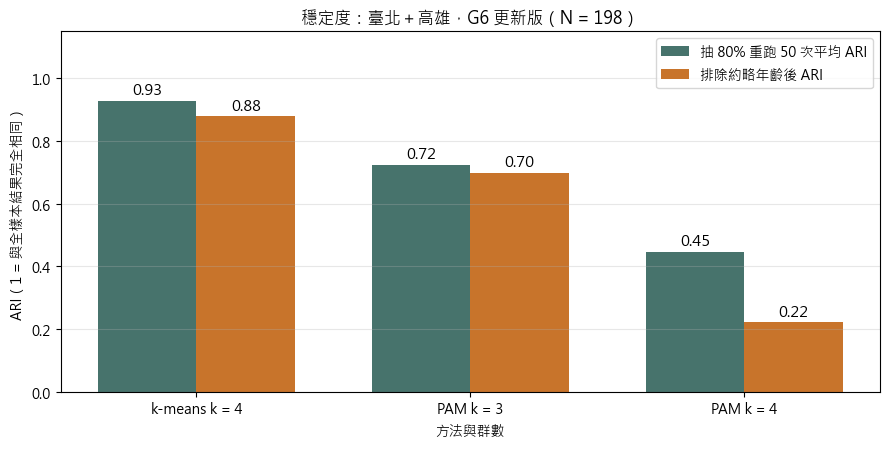

In [7]:
# 穩定度：抽 80% 重跑 50 次（兩方法同一批抽樣）、排除報導／約略年齡者重跑
rng = np.random.default_rng(20261110)
n = len(df); m = int(round(0.8 * n))
age_range = df["age"].max() - df["age"].min()
keep = np.where(df["G1_age_basis"].isin(["birth_date", "existing_source"]).to_numpy())[0]
srows = []
for name, r in results.items():
    k = r["k"]; boot = []
    rng = np.random.default_rng(20261110)
    for rep in range(50):
        idx = np.sort(rng.choice(n, m, replace=False))
        if r["method"] == "k-means":
            l = kmeans(X[idx], k, n_init=10, seed=20261110 + 100 + rep)[0]
        else:
            l = pam(D[np.ix_(idx, idx)], k)[0]
        boot.append(ari(r["lab"][idx], l))
    boot = np.array(boot)
    if r["method"] == "k-means":
        le = kmeans(X[keep], k, n_init=50, seed=20261110 + k)[0]
    else:
        le = pam(D[np.ix_(keep, keep)], k)[0]
    srows.append({"版本": name, "抽 80% 重跑平均 ARI": boot.mean(), "最低 ARI": boot.min(),
                  "ARI ≥ 0.9（%）": 100 * (boot >= 0.9).mean(), "排除約略年齡後 ARI": ari(r["lab"][keep], le),
                  "輪廓係數": silhouette_D(Eu if r["method"] == "k-means" else D, r["lab"])})
stab_tbl = pd.DataFrame(srows).set_index("版本")
print(f"表　穩定度（臺北＋高雄 N = {n}；抽 80%＝{m} 人重跑 50 次；排除報導／約略年齡者 N = {len(keep)}）")
display(stab_tbl.round(3))

# 和舊版 G6 比較（同一批 198 人；舊版切點 k-means 4、PAM 5，並列 PAM 4）
X_old = feat(df_old); D_old = gower(df_old)
old_labels = {"k-means k = 4": relabel(kmeans(X_old, 4, n_init=50, seed=20261110 + 4)[0]),
              "PAM k = 5": relabel(pam(D_old, 5)[0]), "PAM k = 4": relabel(pam(D_old, 4)[0])}
assert sorted(pd.Series(old_labels["k-means k = 4"]).value_counts().tolist()) == [43, 49, 52, 54]
assert sorted(pd.Series(old_labels["PAM k = 5"]).value_counts().tolist()) == [35, 35, 36, 40, 52]
crows = []
for name, r in results.items():
    same = old_labels.get(name)
    crows.append({"版本": name,
                  "與舊版 G6 同版本的 ARI": ari(r["lab"], same) if same is not None else np.nan,
                  "與舊版 G6 同方法切點版的 ARI": ari(r["lab"], old_labels["k-means k = 4" if r["method"] == "k-means" else "PAM k = 5"]),
                  "與政黨本身的 ARI": ari(r["lab"], df["party"]),
                  "與 G5×G6 組合的 ARI": ari(r["lab"], df["first_time"] + df["political_family"])})
cmp_tbl = pd.DataFrame(crows).set_index("版本")
km_main = f"k-means k = {K_KM}"; pam_main = f"PAM k = {K_PAM}"
print(f"表　與舊版 G6、政黨、G5×G6 組合的一致程度（N = {n}）；本樣本 k-means 與 PAM（各自切點）之間 ARI = "
      f"{ari(results[km_main]['lab'], results[pam_main]['lab']):.3f}")
display(cmp_tbl.round(3))

fig, ax = plt.subplots(figsize=(9, 4.6))
names = list(stab_tbl.index)
vals = stab_tbl["抽 80% 重跑平均 ARI"].values
ex = stab_tbl["排除約略年齡後 ARI"].values
x = np.arange(len(names))
ax.bar(x - 0.18, vals, width=0.36, color="#47736C", label="抽 80% 重跑 50 次平均 ARI")
ax.bar(x + 0.18, ex, width=0.36, color="#C8742B", label="排除約略年齡後 ARI")
for xi, v in zip(x - 0.18, vals):
    ax.text(xi, v + 0.02, f"{v:.2f}", ha="center", fontsize=11)
for xi, v in zip(x + 0.18, ex):
    ax.text(xi, v + 0.02, f"{v:.2f}", ha="center", fontsize=11)
ax.set_xticks(x); ax.set_xticklabels(names)
ax.set_ylim(0, 1.15); ax.set_ylabel("ARI（1 = 與全樣本結果完全相同）"); ax.set_xlabel("方法與群數")
ax.set_title(f"穩定度：臺北＋高雄，G6 更新版（N = {n}）")
ax.legend(loc="upper right", fontsize=10); ax.grid(alpha=.3, axis="y")
fig.tight_layout()
fig.savefig(asset_dir / "tk_stability.png", dpi=200)
plt.show()


In [8]:
out = df[["candidate_key", "candidate_name", "office_type", "county_city"]].copy()
for name, r in results.items():
    out[name.replace(" ", "")] = r["lab"]
out_path = asset_dir / "cluster_labels_taipei_kaohsiung_g6v2.csv"
out.to_csv(out_path, index=False, encoding="utf-8-sig")
chk = pd.read_csv(out_path, dtype=str, encoding="utf-8-sig")
assert len(chk) == len(df) and chk["candidate_key"].is_unique
print("已存：", out_path.relative_to(PROJECT_ROOT).as_posix(), "；", len(chk), "列；欄位", list(chk.columns),
      "；SHA-256 =", hashlib.sha256(out_path.read_bytes()).hexdigest())


已存： finding/candidate_cluster_taipei_kaohsiung_g6v2_assets/cluster_labels_taipei_kaohsiung_g6v2.csv ； 198 列；欄位 ['candidate_key', 'candidate_name', 'office_type', 'county_city', 'k-meansk=4', 'PAMk=3', 'PAMk=4'] ；SHA-256 = e54e81083b4e0d8cb525649e3ec964e1a069d9d59ff9971e63fef434635a83db


### 結果說明

**資料差異。** 和舊版相比，只有 G6 不同：北高 198 人中 26 人由 0 改為 1（依組員有來源的親屬與公職證據），政治家族比例由 19.2%（38 人）升為 32.3%（64 人）。其他變數與樣本完全相同。

**選 k（表 3、圖 1–4）。**

- k-means：切點仍是 **k = 4**（離連線 78.29）。
- PAM：切點變成 **k = 3**（離連線 13.16），但 k = 4 為 12.94，兩者幾乎相同；舊版 G6 時切點為 5。PAM 的手肘依然不明顯，k 的選擇對 G6 編碼敏感。
- 輪廓係數仍偏低（k-means k = 4 為 0.270；PAM k = 3、4 為 0.206、0.209）。

**k-means k = 4。** 分群和舊版完全相同（ARI 1.000）：國民黨（54）、大學學歷跨黨（52）、民進黨（49）、無黨籍／小黨（43）。G6 改變只反映在各群的政治家族比例（國民黨群 42.6%、民進黨群 34.7%、大學學歷群 32.7%、無黨籍小黨群 16.3%），不影響分群，因為距離主要由政黨與學歷的虛擬變數決定。

**PAM k = 3（切點）。** 88／63／47 人：第 1 群男性 83%、國民黨 55%、研究所 84%、政治家族 15%（代表人物曾獻瑩）；第 2 群女性 81%、政治家族 75%、民進黨 57%、平均 46.1 歲（代表人物鍾佩玲）；第 3 群大學學歷 66%、無黨籍 51%、平均 54.6 歲、縣市首長比例較高（代表人物薛兆基）。

**PAM k = 4。** 70／51／45／32 人：年長男性、國民黨 57%（57.4 歲）；女性 90%、政治家族 77%；大學學歷 78%、民進黨 44%；首次參選 91%、無黨籍 56%。和舊版 G6 的 PAM k = 4 ARI 0.620。

**穩定度。**

| 版本 | 抽 80% 重跑平均 ARI | ARI ≥ 0.9 的比例 | 排除約略年齡後 ARI | 與政黨 ARI | 與 G5×G6 ARI |
| --- | --- | --- | --- | --- | --- |
| k-means k = 4 | 0.929 | 64% | 0.879 | 0.553 | 0.010 |
| PAM k = 3 | 0.724 | 50% | 0.699 | 0.168 | 0.172 |
| PAM k = 4 | 0.447 | 8% | 0.221 | 0.122 | 0.301 |

PAM k = 3 比舊版各 PAM 版本穩定許多（舊版 0.38–0.42），但最低 ARI 只有 0.041，仍有部分抽樣結果大幅重組。本樣本 k-means 與 PAM k = 3 之間 ARI 為 0.156。

**解讀與限制。** G6 補齊後，「女性＋政治家族」成為 PAM 中明顯且相對穩定的一群（女性候選人中有政治家族背景的比例高），這是舊版看不到的結構；k-means 仍只反映政黨與學歷。G6 的 4 個定義邊界個案（沈伯洋曾祖父為日治時期村里長、陳瑩父親與許甫配偶為政務任命職、吳銘賜姊妹關係為推定）若改判，結果可能小幅變動。首長只有 11 人。

<!-- Completion: run all cells in order from a clean kernel and save the actual
outputs in this ipynb. Inspect the notebook's code, tables, and figures for
readable labels, nonoverlapping text, and agreement with the takeaways. Deliver
the executed ipynb directly and record its actual execution status. Produce HTML
only when separately requested, never as a default export or a condition of completion. -->
